# Device-level noise: relaxation, crosstalk and idling

The [noise tutorial](noise.ipynb) covers Pauli and coherent errors placed after gates. Real devices do more:

- qubits **relax** towards $|0\rangle$ (T1) and **dephase** (T2), a channel that is not unital and not a Pauli channel;
- a two-qubit gate disturbs its **spectators**, the neighbours it does not act on (crosstalk);
- qubits waiting for others keep decohering, and coupled idle pairs pick up an **always-on $ZZ$**;
- states are **prepared** imperfectly, and $1\to0$ readout flips are usually likelier than $0\to1$.

This notebook builds such a device model, checks it against exact density-matrix simulation, breaks the error down by source, shows why the non-unital part cannot be replaced by its Pauli twirl, and runs the same model at a size no density matrix reaches.

**How general channels are simulated.** Any channel can be written in the Pauli basis as $\mathcal{E}(\rho) = \sum_{A,B} \chi_{AB}\, A\rho B$. Its diagonal $\chi_{AA}$ is a Pauli channel (the Pauli twirl), handled as Pauli faults: each one flips the signs of some later dressed rotations. The off-diagonal *coherences* $\chi_{AB}$ act with $A$ on the ket and $B$ on the bra, so they flip the two sides differently and contribute a transition amplitude $\langle\phi_B| B O A |\phi_A\rangle$ between two MPS. For amplitude damping, the coherences $(I, Z)$ and $(X, Y)$ are exactly what pushes population back to $|0\rangle$. Configurations with zero or one noisy location are still summed exactly; those with more are sampled, with coherences drawn by $|\chi_{AB}|$ and their complex phases carried as weights (a quasi-probability).

In [1]:
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from qibo import gates

from mpstab import HSMPO
from mpstab.hamiltonians import pauli_string_to_hamiltonian
from mpstab.models.ansatze import ParametricKickedIsing
from mpstab.noise import (
    CoherentError,
    DepolarizingError,
    NoiseModel,
    PauliError,
    ReadoutError,
    StatePreparationError,
    ThermalRelaxationError,
)
from mpstab.noise.compile import compile_noise
from mpstab.noise.events import KrausChannel

np.set_printoptions(precision=4, suppress=True)
BLUE, ORANGE, INK, GREY = "#2a78d6", "#eb8a1c", "#0b0b0b", "#9a9a9a"

## The circuit and the observables

A kicked Ising chain on 8 qubits, as in the basic tutorial: its couplings are `CNOT · RZ · CNOT`, so CNOTs are the two-qubit gates, and `delta_h` sets how much magic the circuit holds. We look at two observables: the nearest-neighbour energy $\sum_i Z_iZ_{i+1}$ and the magnetization $\frac1n\sum_i Z_i$, which is what relaxation acts on most directly.

In [2]:
NQUBITS = 8
ansatz = ParametricKickedIsing(nqubits=NQUBITS, n_steps=3, delta_h=0.2)
circuit = ansatz.circuit
hsmpo = HSMPO(ansatz)


def z_string(*sites, n=NQUBITS):
    return "".join("Z" if q in sites else "I" for q in range(n))


energy = {z_string(i, i + 1): 1.0 for i in range(NQUBITS - 1)}
magnetization = {z_string(i): 1.0 / NQUBITS for i in range(NQUBITS)}

print(f"{NQUBITS} qubits, {len(circuit.queue)} gates, {hsmpo.n_magic_gates} magic")
print(f"noiseless energy        {hsmpo.expectation(energy):+.5f}")
print(f"noiseless magnetization {hsmpo.expectation(magnetization):+.5f}")

8 qubits, 111 gates, 24 magic
noiseless energy        +0.56761
noiseless magnetization -0.06829


## A device noise model

The qubits sit on a line. Times are in microseconds; the values are typical of current superconducting devices, with a single-qubit gate of 30 ns and a CNOT of 80 ns.

| source | model | rule |
|---|---|---|
| relaxation during gates | `ThermalRelaxationError(T1, T2, duration)` | `add` after every gate |
| two-qubit gate error | `DepolarizingError` | `add` after every CNOT |
| crosstalk | coherent $ZZ$ between each CNOT qubit and its spectators | `add_crosstalk` |
| idling | relaxation for one moment, and a residual $ZZ$ on idle coupled pairs | `add_idle` |
| preparation | $X$ flip of the initial state | `add(StatePreparationError)` |
| readout | asymmetric bit flips, $p_{0\to1} < p_{1\to0}$ | `add(ReadoutError(p0, p1))` |

- `add_crosstalk(error, coupling, gate)` puts a two-qubit error on every `(gate qubit, spectator)` edge of the coupling graph, a one-qubit error on every spectator.
- `add_idle(error, qubits, coupling)` puts it on every qubit, or every coupled pair, left idle in a *moment*. Moments layer the gate queue in order: a gate starts right after the last gate on its qubits, and never before the gate queued ahead of it.
- A coherent error joins the rotation chain like a magic gate, so a coherent $ZZ$ on every idle pair of every moment would make the chain much longer. The residual idle $ZZ$ is usually suppressed by dynamical decoupling or twirled by randomized compiling anyway, so we use `CoherentError.twirled()`: the stochastic $ZZ$ error the rotation becomes under twirling, which costs nothing.

`device_noise` builds the model from a set of sources, so we can switch them on one by one later, and can replace the thermal relaxation by its Pauli twirl.

In [3]:
T1, T2 = 100.0, 80.0       # microseconds
T_1Q, T_2Q = 0.03, 0.08    # gate durations, microseconds
LINE = [(q, q + 1) for q in range(NQUBITS - 1)]
SOURCES = ("relaxation", "gate", "crosstalk", "idle", "spam")


def pauli_twirl(error):
    # The Pauli channel on the diagonal of a one-qubit channel's process matrix.
    chi = KrausChannel(0, (0,), error.kraus).chi
    return PauliError({p: chi[(p, p)].real for p in "XYZ" if (p, p) in chi})


def device_noise(sources=SOURCES, relaxation="exact", crosstalk="coherent", coupling=LINE):
    def relax(duration):
        error = ThermalRelaxationError(T1, T2, duration)
        return error if relaxation == "exact" else pauli_twirl(error)

    noise = NoiseModel()
    if "relaxation" in sources:
        noise.add(relax(T_1Q), (gates.RX, gates.RZ, gates.H))
        noise.add(relax(T_2Q), gates.CNOT)
    if "gate" in sources:
        noise.add(DepolarizingError(5e-3), gates.CNOT)
    if "crosstalk" in sources:
        zz = CoherentError("ZZ", 0.03)
        noise.add_crosstalk(zz if crosstalk == "coherent" else zz.twirled(), coupling, gates.CNOT)
    if "idle" in sources:
        noise.add_idle(relax(T_2Q))
        noise.add_idle(CoherentError("ZZ", 0.02).twirled(), coupling=coupling)
    if "spam" in sources:
        noise.add(StatePreparationError(0.005))
        noise.add(ReadoutError(0.01, 0.03))
    return noise


noise = device_noise()
events = noise.events(circuit)
print(f"{len(events)} noise events:", dict(Counter(type(e).__name__ for e in events)))
for rule in noise.rules:
    print(f"  {rule.kind:12s} {type(rule.error).__name__:24s} {len(rule.events(circuit)):4d} events")

926 noise events: {'KrausChannel': 536, 'PauliChannel': 318, 'CoherentRotation': 72}
  gate         ThermalRelaxationError     69 events
  gate         ThermalRelaxationError     84 events
  gate         DepolarizingError          42 events
  crosstalk    CoherentError              72 events
  idle         ThermalRelaxationError    383 events
  idle         PauliError                268 events
  preparation  StatePreparationError       8 events
  readout      ReadoutError                0 events


`events` resolves the model on the circuit. The relaxation and idle rules become `KrausChannel` events, the crosstalk becomes `CoherentRotation`s, and the rest are Pauli channels. Readout acts on the measured bits rather than the state, so it has no events: it is folded into the observable. With asymmetric flips, a measured Pauli factor $P$ reads as $(1-p_0-p_1)P + (p_1-p_0)I$, so a term also feeds its lower-weight subterms and the constant:

In [4]:
constant, terms = noise.readout_observable({z_string(0, 1): 1.0}, NQUBITS)
print("Z0 Z1 as read out:", f"{constant:+.6f} +", {p: round(float(c), 6) for p, c in terms.items()})

Z0 Z1 as read out: +0.000400 + {'ZZIIIIII': 0.9216, 'ZIIIIIII': 0.0192, 'IZIIIIII': 0.0192}


## Checking against the exact density matrix

`noise.apply(circuit)` gives the same noisy circuit as a qibo density-matrix circuit, with the Kraus channels as `KrausChannel` gates. Together with `readout_observable` it gives the exact value.

In [5]:
def exact_expectation(noise, observable, circuit=circuit):
    constant, terms = noise.readout_observable(observable, circuit.nqubits)
    rho = noise.apply(circuit)().state()
    return constant + sum(
        c * pauli_string_to_hamiltonian(p).expectation_from_state(rho) for p, c in terms.items()
    )


for name, observable in (("energy", energy), ("magnetization", magnetization)):
    start = time.perf_counter()
    result = hsmpo.noisy_expectation(observable, noise, n_samples=1000, seed=0)
    elapsed = time.perf_counter() - start
    exact = exact_expectation(noise, observable)
    print(f"{name}: mpstab {result.mean:+.5f} +- {result.stderr:.5f} ({elapsed:.1f} s),"
          f" exact {exact:+.5f}, deviation {abs(result.mean - exact) / result.stderr:.1f} sigma")
    print(f"  stratum weights {np.round(result.stratum_weights, 3)},"
          f" {result.n_patterns} sign patterns, {result.n_transitions} transition amplitudes")

[Qibo 0.3.6|INFO|2026-11-17 23:03:38]: Using numpy backend on /CPU:0


energy: mpstab +0.62243 +- 0.00320 (24.4 s), exact +0.62524, deviation 0.9 sigma
  stratum weights [0.546 0.546 0.391], 711 sign patterns, 1761 transition amplitudes


magnetization: mpstab -0.01722 +- 0.00069 (23.1 s), exact -0.01760, deviation 0.5 sigma
  stratum weights [0.546 0.546 0.391], 711 sign patterns, 1761 transition amplitudes


The stratum weights no longer sum to one: coherences enter with $|\chi_{AB}|$, so the total is a quasi-probability mass larger than one, and the excess sets how much the sampled part costs in variance. `n_transitions` counts the transition amplitudes, the price of the coherences.

## Relaxation is not a Pauli channel

A common shortcut replaces relaxation by its Pauli twirl, which is a Pauli channel and much cheaper. The twirl keeps the decay of coherences but drops the drift towards $|0\rangle$: on average it pushes every $\langle Z\rangle$ towards 0 rather than towards $+1$. The magnetization profile shows the difference. The exact profile comes from the density matrix; `mpstab` evaluates each $\langle Z_i\rangle$ with its own light cone.

In [6]:
sites = np.arange(NQUBITS)
ideal_z = np.array([hsmpo.expectation(z_string(i)) for i in sites])

# Without preparation and readout errors, to compare what the gates do to the state.
state_noise = device_noise(sources=("relaxation", "gate", "crosstalk", "idle"))
state_twirl = device_noise(sources=("relaxation", "gate", "crosstalk", "idle"), relaxation="twirled")
rho_exact = state_noise.apply(circuit)().state()
rho_twirl = state_twirl.apply(circuit)().state()
exact_z = np.array([pauli_string_to_hamiltonian(z_string(i)).expectation_from_state(rho_exact) for i in sites])
twirl_z = np.array([pauli_string_to_hamiltonian(z_string(i)).expectation_from_state(rho_twirl) for i in sites])

start = time.perf_counter()
mpstab_z = [hsmpo.noisy_expectation(z_string(i), state_noise, n_samples=300, seed=i) for i in sites]
print(f"{NQUBITS} single-site values in {time.perf_counter() - start:.1f} s")

8 single-site values in 76.4 s


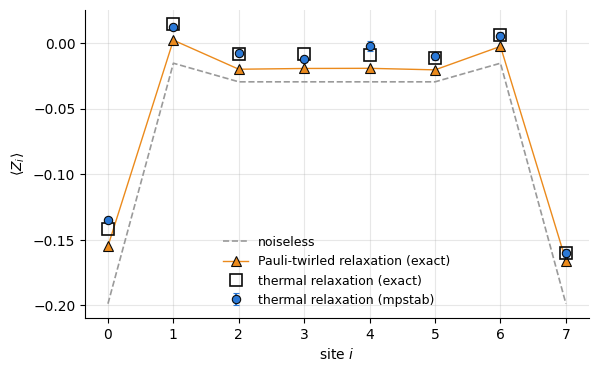

exact - twirled, per site: [0.0134 0.0119 0.0116 0.0108 0.0099 0.0091 0.0083 0.0058]
mean bias of the twirl on <Z_i>: +0.0101


In [7]:
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.plot(sites, ideal_z, "--", color=GREY, lw=1.2, label="noiseless")
ax.plot(sites, twirl_z, "^-", color=ORANGE, ms=7, mec=INK, mew=0.8, lw=1, label="Pauli-twirled relaxation (exact)")
ax.plot(sites, exact_z, "s", color=INK, ms=9, mfc="none", mew=1.2, label="thermal relaxation (exact)")
ax.errorbar(sites, [r.mean for r in mpstab_z], yerr=[r.stderr for r in mpstab_z], fmt="o", color=BLUE,
            ms=6, mec=INK, mew=0.8, capsize=2, label="thermal relaxation (mpstab)")
ax.set_xlabel("site $i$")
ax.set_ylabel(r"$\langle Z_i \rangle$")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(alpha=0.3)
ax.legend(frameon=False, fontsize=9)
plt.show()

shift = exact_z - twirl_z
print("exact - twirled, per site:", shift)
print(f"mean bias of the twirl on <Z_i>: {shift.mean():+.4f}")

## Error budget

Which source matters most? Switch them on one at a time and compare each shift of the energy from its noiseless value. Each bar is one `mpstab` run, and the black marks are the exact values. Each source alone takes a second or two; the full model costs more because its noisy locations combine, which is what the sampled $k \ge 2$ stratum pays for.

In [8]:
ideal_energy = hsmpo.expectation(energy)
budget = {}
for source in SOURCES:
    alone = device_noise(sources=(source,))
    start = time.perf_counter()
    result = hsmpo.noisy_expectation(energy, alone, n_samples=500, seed=1)
    budget[source] = (
        result.mean - ideal_energy,
        result.stderr,
        exact_expectation(alone, energy) - ideal_energy,
        time.perf_counter() - start,
    )
    print(f"{source:10s} shift {budget[source][0]:+.5f} +- {budget[source][1]:.5f}"
          f"  (exact {budget[source][2]:+.5f}, {budget[source][3]:.1f} s)")

relaxation shift -0.01169 +- 0.00016  (exact -0.01166, 2.1 s)


gate       shift -0.04872 +- 0.00011  (exact -0.04869, 1.6 s)


crosstalk  shift +0.31065 +- 0.00000  (exact +0.31065, 0.3 s)


idle       shift -0.06417 +- 0.00168  (exact -0.06426, 3.6 s)


spam       shift -0.06519 +- 0.00001  (exact -0.06519, 0.4 s)


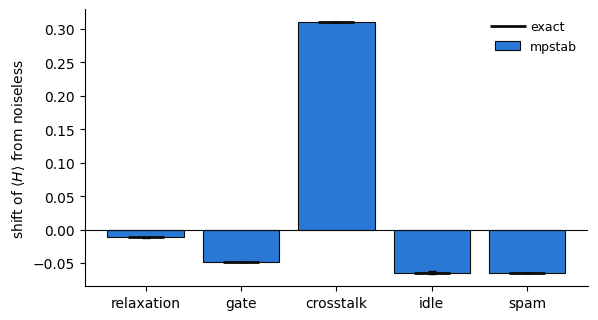

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 3.6))
x = np.arange(len(SOURCES))
shifts, errors, exacts, _ = map(np.array, zip(*budget.values()))
ax.bar(x, shifts, yerr=errors, color=BLUE, edgecolor=INK, lw=0.8, capsize=3, label="mpstab")
ax.plot(x, exacts, "_", color=INK, ms=26, mew=2, label="exact")
ax.axhline(0, color=INK, lw=0.8)
ax.set_xticks(x, SOURCES)
ax.set_ylabel(r"shift of $\langle H\rangle$ from noiseless")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.show()

## Coherent or twirled crosstalk?

The error budget is dominated by the coherent crosstalk. That is no accident: the couplings of this circuit are themselves $ZZ$ rotations (`CNOT · RZ · CNOT`), so a spurious $ZZ$ on a neighbouring pair shifts the Ising angles directly, and these shifts add up coherently, in amplitude, from step to step.

Under randomized compiling the same error becomes its Pauli twirl, a stochastic $ZZ$ with probability $\sin^2(\theta/2)$, which only adds in probability. It is also much cheaper: each coherent rotation joins the chain of dressed rotations like a magic gate, while the twirl leaves the chain alone.

In [10]:
for mode in ("coherent", "twirled"):
    model = device_noise(sources=("crosstalk",), crosstalk=mode)
    compiled = compile_noise(hsmpo, model.events(circuit))
    start = time.perf_counter()
    result = hsmpo.noisy_expectation(energy, model, n_samples=500, seed=2)
    print(f"{mode:9s}: {len(compiled.generators):3d} rotations in the chain, "
          f"<H> = {result.mean:+.5f} +- {result.stderr:.5f} ({time.perf_counter() - start:.2f} s),"
          f" exact {exact_expectation(model, energy):+.5f}")

coherent :  96 rotations in the chain, <H> = +0.87826 +- 0.00000 (0.01 s), exact +0.87826


twirled  :  24 rotations in the chain, <H> = +0.56378 +- 0.00000 (0.42 s), exact +0.56378


## Under the hood

`compile_noise` pulls every event into the Clifford frame of the surrogate. For the full device model:

In [11]:
compiled = compile_noise(hsmpo, noise.events(circuit))
print(f"rotations in the chain   {len(compiled.generators)} ({hsmpo.n_magic_gates} magic gates + coherent errors)")
print(f"noise locations          {len(compiled.location_probs)}")
print(f"Pauli faults             {len(compiled.fault_probs)}")
print(f"coherences               {len(compiled.coherence_weights)}")

for name, observable in (("the energy", energy), ("Z_0", {z_string(0): 1.0})):
    dressed = [compiled.dress_observable(p)[0] for p in observable]
    restricted = compiled.restricted_to(dressed)
    print(f"\nrestricted to the light cone of {name}:")
    print(f"rotations {len(restricted.generators)}, locations {len(restricted.location_probs)}, "
          f"faults {len(restricted.fault_probs)}, coherences {len(restricted.coherence_weights)}")

rotations in the chain   96 (24 magic gates + coherent errors)
noise locations          854
Pauli faults             2514
coherences               1072

restricted to the light cone of the energy:
rotations 94, locations 842, faults 2491, coherences 1072

restricted to the light cone of Z_0:
rotations 60, locations 576, faults 1656, coherences 734


`restricted_to` walks the chain backwards from the observable. A rotation stays only if it can still change the observable, and a noise location stays only if one of its Paulis can. A Kraus channel whose Paulis all commute with what is left acts as the identity, because it is trace preserving, so it is dropped whole. When a channel does stay, its coherences spread the observable ($O \to B O A$), so its Paulis join the light cone for everything before it. All of this is exact. The energy touches the whole chain, so little is dropped for it. A single $Z_0$ at the edge keeps about two thirds of the circuit on these 8 qubits; on a longer chain the share it keeps shrinks with the length, which is what keeps local observables cheap, as the last section shows.

## Beyond density matrices

What makes the device model expensive is now clear, and it decides what scales:

- every coherent crosstalk rotation lengthens the rotation chain, so on a long chain they cost bond dimension. We use the twirled crosstalk, as randomized compiling would;
- idle noise grows with the circuit depth. This ansatz queues its couplings as a staircase along the chain, so its depth, and with it the number of idle windows, grows with $n$. A device would run the couplings as a brickwork of constant depth, and a brickwork circuit should be passed in for idle noise to stay local. Here we leave idling out.

With these choices the device model runs on 60 qubits, where a density matrix would have $4^{60}$ entries. A local $Z_iZ_{i+1}$ in the middle of the chain has a light cone of fixed size, so its value and its cost hardly depend on the chain length: both runs give the bulk value of an infinite chain.

In [12]:
for n in (16, 60):
    big = ParametricKickedIsing(nqubits=n, n_steps=3, delta_h=0.2)
    surrogate = HSMPO(big, max_bond_dimension=32)
    line = [(q, q + 1) for q in range(n - 1)]
    model = device_noise(
        sources=("relaxation", "gate", "crosstalk", "spam"), crosstalk="twirled", coupling=line
    )
    local = z_string(n // 2, n // 2 + 1, n=n)
    start = time.perf_counter()
    result = surrogate.noisy_expectation(local, model, n_samples=1000, seed=3)
    print(f"n={n:3d}: {len(model.events(big.circuit)):5d} noise events, ideal {surrogate.expectation(local):+.4f},"
          f" noisy {result.mean:+.4f} +- {result.stderr:.4f} ({time.perf_counter() - start:.1f} s)")

n= 16:   595 noise events, ideal +0.1123, noisy +0.0891 +- 0.0003 (2.6 s)


n= 60:  2355 noise events, ideal +0.1123, noisy +0.0890 +- 0.0003 (5.9 s)


## Summary

```python
noise = NoiseModel()
noise.add(ThermalRelaxationError(t1, t2, gate_time))           # after every gate: T1/T2
noise.add(DepolarizingError(5e-3), gates.CNOT)                  # gate error
noise.add_crosstalk(CoherentError("ZZ", 0.03), coupling, gates.CNOT)  # spectators
noise.add_idle(ThermalRelaxationError(t1, t2, moment_time))     # idle qubits
noise.add_idle(CoherentError("ZZ", 0.02).twirled(), coupling=coupling)  # idle pairs
noise.add(StatePreparationError(0.005))                         # |0> prepared as |1>
noise.add(ReadoutError(0.01, 0.03))                             # 0->1 and 1->0 flips

result = hsmpo.noisy_expectation(observable, noise, n_samples=1000, seed=0)
```

- `AmplitudeDampingError`, `ThermalRelaxationError` and `KrausError` (any Kraus operators) are simulated exactly. Their non-Pauli part costs transition amplitudes and a quasi-probability overhead, both shown in the result.
- `CoherentError.twirled()` trades a coherent error for the Pauli error it becomes under twirling, at no cost in rotations.
- `noise.scaled(factor)` scales probabilities, angles, damping rates and relaxation *times* alike, for zero-noise extrapolation.